# AgroSense Analytics — Projeto Aplicado II
## Etapa 2: Definição do Produto Analítico e Dicionário de Dados

**Equipe:** Henrique Sarmento, Felipe Magalhães de Melo Costa, Jefferson Candido Moreira, Karla Maria Ramos da Silva  
**Startup:** AgroSense Analytics  
**Repositório Oficial:** [GitHub - henri-sarmento/ProjetoAplicado2](https://github.com/henri-sarmento/ProjetoAplicado2)  
**Dataset:** [PlantVillage (Kaggle)](https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset) — Subconjunto `color` (RGB 256x256)

---

### Objetivos da Etapa 2
1. **Definição de Bibliotecas e Ambiente Python** para processamento e análise de imagens;
2. **Estruturação do Dicionário de Dados** de metadados e atributos da imagem;
3. **Análise Exploratória de Dados (EDA)** detalhando distribuição de classes, integridade matricial e métricas fotométricas;
4. **Fundamentação teórica dos métodos analíticos** e métricas de acurácia para a fase preditiva.


In [4]:
# 1. Importação das Bibliotecas Essenciais
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Configuração de exibição
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('Ambiente Python configurado com sucesso!')
print(f'Pandas versão: {pd.__version__}')
print(f'NumPy versão: {np.__version__}')


Ambiente Python configurado com sucesso!
Pandas versão: 3.0.5
NumPy versão: 2.5.3


---
## 2. Estruturação do Dicionário de Dados

Como as imagens do PlantVillage não residem nativamente em uma tabela relacional, estruturamos uma modelagem de metadados rica em informações de negócio e visão computacional.

Abaixo é instanciado o **DataFrame do Dicionário de Dados**, detalhando os campos, sua semântica e tipagem técnica.


In [5]:
# 2. Construção e Exibição do Dicionário de Dados Estruturado
dicionario_dados = [
    {
        'Coluna': 'caminho_arquivo',
        'Descrição': 'Caminho relativo do arquivo de imagem a partir da raiz do repositório.',
        'Tipo de dado': 'string',
        'Exemplo': 'plantvillage dataset/color/Tomato___Target_Spot/0a0b1c2d.jpg'
    },
    {
        'Coluna': 'nome_arquivo',
        'Descrição': 'Nome físico do arquivo de imagem com extensão.',
        'Tipo de dado': 'string',
        'Exemplo': '0a0b1c2d-96e0-4a87-8d07-299f0e263d59___UNREST.JPG'
    },
    {
        'Coluna': 'especie_cultura',
        'Descrição': 'Espécie vegetal da folha analisada (ex: Tomate, Maçã, Milho, Batata).',
        'Tipo de dado': 'string',
        'Exemplo': 'Tomato'
    },
    {
        'Coluna': 'condicao_sanitaria',
        'Descrição': 'Diagnóstico da condição fitossanitária (patologia diagnosticada ou saudável).',
        'Tipo de dado': 'string',
        'Exemplo': 'Target_Spot'
    },
    {
        'Coluna': 'classe_rotulo',
        'Descrição': 'Rótulo completo de classificação (cultura + patologia) que compõe as 38 classes alvo.',
        'Tipo de dado': 'string',
        'Exemplo': 'Tomato___Target_Spot'
    },
    {
        'Coluna': 'is_saudavel',
        'Descrição': 'Indicador booleano que sinaliza se a folha está saudável (True) ou doente (False).',
        'Tipo de dado': 'booleano',
        'Exemplo': False
    },
    {
        'Coluna': 'largura_px',
        'Descrição': 'Largura da imagem expressa em número de pixels.',
        'Tipo de dado': 'inteiro',
        'Exemplo': 256
    },
    {
        'Coluna': 'altura_px',
        'Descrição': 'Altura da imagem expressa em número de pixels.',
        'Tipo de dado': 'inteiro',
        'Exemplo': 256
    },
    {
        'Coluna': 'total_pixels',
        'Descrição': 'Quantidade total de pixels da matriz espacial (largura * altura).',
        'Tipo de dado': 'inteiro',
        'Exemplo': 65536
    },
    {
        'Coluna': 'qtd_canais',
        'Descrição': 'Quantidade de canais matriciais cromáticos da imagem (RGB = 3).',
        'Tipo de dado': 'inteiro',
        'Exemplo': 3
    },
    {
        'Coluna': 'espaco_cores',
        'Descrição': 'Modo de representação de cores da imagem (ex: RGB, L, CMYK).',
        'Tipo de dado': 'string',
        'Exemplo': 'RGB'
    },
    {
        'Coluna': 'tamanho_arquivo_kb',
        'Descrição': 'Tamanho físico do arquivo armazenado em disco em kilobytes.',
        'Tipo de dado': 'float',
        'Exemplo': 14.85
    },
    {
        'Coluna': 'formato_arquivo',
        'Descrição': 'Formato e compressão do arquivo da imagem.',
        'Tipo de dado': 'string',
        'Exemplo': 'JPEG'
    },
    {
        'Coluna': 'media_canal_r',
        'Descrição': 'Intensidade luminosa média de pixels no canal Vermelho (escala 0-255).',
        'Tipo de dado': 'float',
        'Exemplo': 124.32
    },
    {
        'Coluna': 'media_canal_g',
        'Descrição': 'Intensidade luminosa média de pixels no canal Verde (escala 0-255).',
        'Tipo de dado': 'float',
        'Exemplo': 145.18
    },
    {
        'Coluna': 'media_canal_b',
        'Descrição': 'Intensidade luminosa média de pixels no canal Azul (escala 0-255).',
        'Tipo de dado': 'float',
        'Exemplo': 102.40
    },
    {
        'Coluna': 'desvio_canal_r',
        'Descrição': 'Desvio padrão dos valores de pixel no canal Vermelho.',
        'Tipo de dado': 'float',
        'Exemplo': 42.15
    },
    {
        'Coluna': 'desvio_canal_g',
        'Descrição': 'Desvio padrão dos valores de pixel no canal Verde.',
        'Tipo de dado': 'float',
        'Exemplo': 38.60
    },
    {
        'Coluna': 'desvio_canal_b',
        'Descrição': 'Desvio padrão dos valores de pixel no canal Azul.',
        'Tipo de dado': 'float',
        'Exemplo': 45.92
    }
]

df_dicionario = pd.DataFrame(dicionario_dados)

# Exibição tabulada
print(f'=== DICIONÁRIO DE DADOS ESTRUTURADO (Total de colunas: {len(df_dicionario)}) ===')
display(df_dicionario)


=== DICIONÁRIO DE DADOS ESTRUTURADO (Total de colunas: 19) ===


,Coluna,Descrição,Tipo de dado,Exemplo
0,caminho_arquivo,Caminho relativo do arquivo de imagem a partir da raiz do repositório.,string,plantvillage dataset/color/Tomato___Target_Spot/0a0b1c2d.jpg
1,nome_arquivo,Nome físico do arquivo de imagem com extensão.,string,0a0b1c2d-96e0-4a87-8d07-299f0e263d59___UNREST.JPG
2,especie_cultura,"Espécie vegetal da folha analisada (ex: Tomate, Maçã, Milho, Batata).",string,Tomato
3,condicao_sanitaria,Diagnóstico da condição fitossanitária (patologia diagnosticada ou saudável).,string,Target_Spot
4,classe_rotulo,Rótulo completo de classificação (cultura + patologia) que compõe as 38 classes alvo.,string,Tomato___Target_Spot
5,is_saudavel,Indicador booleano que sinaliza se a folha está saudável (True) ou doente (False).,booleano,False
6,largura_px,Largura da imagem expressa em número de pixels.,inteiro,256
7,altura_px,Altura da imagem expressa em número de pixels.,inteiro,256
8,total_pixels,Quantidade total de pixels da matriz espacial (largura * altura).,inteiro,65536
9,qtd_canais,Quantidade de canais matriciais cromáticos da imagem (RGB = 3).,inteiro,3


---
## 3. Carga e Inspeção do DataFrame de Metadados

Carregamos o DataFrame consolidado a partir do arquivo `metadados_plantvillage.csv` gerado pelo pipeline de extração.


In [6]:
# 3. Carregamento do DataFrame consolidado
caminhos_possiveis = [
    Path('../data/metadados_plantvillage.csv'),
    Path('ProjetoAplicado2/data/metadados_plantvillage.csv'),
    Path('data/metadados_plantvillage.csv')
]

csv_path = None
for p in caminhos_possiveis:
    if p.exists():
        csv_path = p
        break

if csv_path is None:
    raise FileNotFoundError('Arquivo metadados_plantvillage.csv não encontrado. Execute extract_metadata.py!')

print(f'Carregando metadados de: {csv_path.resolve()}')
df_meta = pd.read_csv(csv_path)

print(f'Dimensões do DataFrame: {df_meta.shape[0]:,} linhas x {df_meta.shape[1]} colunas')
df_meta.head()


Carregando metadados de: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\ProjetoAplicado2\data\metadados_plantvillage.csv
Dimensões do DataFrame: 54,305 linhas x 19 colunas


,caminho_arquivo,nome_arquivo,especie_cultura,condicao_sanitaria,classe_rotulo,is_saudavel,largura_px,altura_px,total_pixels,qtd_canais,espaco_cores,tamanho_arquivo_kb,formato_arquivo,media_canal_r,media_canal_g,media_canal_b,desvio_canal_r,desvio_canal_g,desvio_canal_b
0,plantvillage dataset/color/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG,00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG,Apple,Apple_scab,Apple___Apple_scab,False,256,256,65536,3,RGB,9.39,JPEG,110.66,130.18,119.86,44.75,35.31,57.45
1,plantvillage dataset/color/Apple___Apple_scab/01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003.JPG,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003.JPG,Apple,Apple_scab,Apple___Apple_scab,False,256,256,65536,3,RGB,9.87,JPEG,84.16,97.56,103.14,30.02,23.17,47.93
2,plantvillage dataset/color/Apple___Apple_scab/01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Scab 3112.JPG,01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Scab 3112.JPG,Apple,Apple_scab,Apple___Apple_scab,False,256,256,65536,3,RGB,11.72,JPEG,92.54,125.73,116.03,34.04,30.81,37.41
3,plantvillage dataset/color/Apple___Apple_scab/0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Scab 3037.JPG,0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Scab 3037.JPG,Apple,Apple_scab,Apple___Apple_scab,False,256,256,65536,3,RGB,19.02,JPEG,129.90,125.65,114.41,58.72,57.26,65.65
4,plantvillage dataset/color/Apple___Apple_scab/023123cb-7b69-4c9f-a521-766d7c8543bb___FREC_Scab 3487.JPG,023123cb-7b69-4c9f-a521-766d7c8543bb___FREC_Scab 3487.JPG,Apple,Apple_scab,Apple___Apple_scab,False,256,256,65536,3,RGB,8.69,JPEG,86.71,101.71,101.43,36.07,28.76,43.55


In [7]:
# 3.1 Verificação de Tipos e Integridade
print('--- Informações Estruturais do DataFrame (info) ---')
df_meta.info()

print()
print('--- Verificação de Valores Ausentes / Nulos ---')
nulos = df_meta.isnull().sum()
print(nulos[nulos > 0] if (nulos > 0).any() else 'Nenhum valor nulo identificado no acervo!')


--- Informações Estruturais do DataFrame (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 54305 entries, 0 to 54304
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   caminho_arquivo     54305 non-null  str    
 1   nome_arquivo        54305 non-null  str    
 2   especie_cultura     54305 non-null  str    
 3   condicao_sanitaria  54305 non-null  str    
 4   classe_rotulo       54305 non-null  str    
 5   is_saudavel         54305 non-null  bool   
 6   largura_px          54305 non-null  int64  
 7   altura_px           54305 non-null  int64  
 8   total_pixels        54305 non-null  int64  
 9   qtd_canais          54305 non-null  int64  
 10  espaco_cores        54305 non-null  str    
 11  tamanho_arquivo_kb  54305 non-null  float64
 12  formato_arquivo     54305 non-null  str    
 13  media_canal_r       54305 non-null  float64
 14  media_canal_g       54305 non-null  float64
 15  media_canal_

In [8]:
# 3.2 Estatísticas Descritivas Numéricas
df_meta.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]


,count,mean,std,min,50%,max
largura_px,54305.0,256.000000,0.000000,256.00,256.00,256.00
altura_px,54305.0,256.000000,0.000000,256.00,256.00,256.00
total_pixels,54305.0,65536.000000,0.000000,65536.00,65536.00,65536.00
qtd_canais,54305.0,3.000018,0.004291,3.00,3.00,4.00
tamanho_arquivo_kb,54305.0,15.299604,4.319364,3.36,15.58,118.80
media_canal_r,54305.0,118.937948,20.107744,8.30,118.52,233.15
media_canal_g,54305.0,124.721230,20.113976,8.66,123.70,237.85
media_canal_b,54305.0,104.639458,23.200879,5.73,105.13,225.53
desvio_canal_r,54305.0,44.910275,12.560865,7.80,45.99,94.06
desvio_canal_g,54305.0,38.257966,10.997279,9.79,37.59,95.62


---
## 4. Análise Exploratória de Dados (EDA)

### 4.1 Homogeneidade Dimensional e Fisiografia das Imagens
Avaliamos se todas as imagens mantêm a resolução padronizada de $256 	x 256$ pixels e 3 canais RGB, requisito indispensável para redes neurais convolucionais.


In [9]:
# 4.1 Validação de Resolução e Espaço de Cores
resolucoes = df_meta.groupby(['largura_px', 'altura_px', 'qtd_canais', 'espaco_cores']).size().reset_index(name='total_imagens')
print('Tabela de Homogeneidade Espacial e Cromática:')
display(resolucoes)

# Diagnóstico de Qualidade de Dados (Data Hygiene)
if len(resolucoes) == 1:
    print('100% das imagens possuem rigorosamente 256x256 pixels e 3 canais RGB!')
else:
    rgba_imgs = df_meta[df_meta['espaco_cores'] == 'RGBA']
    print(f'-> Diagnóstico de Qualidade: Identificadas {len(rgba_imgs)} imagem(ns) com 4 canais (RGBA) entre as {len(df_meta):,} imagens.')
    print(f'-> Resolução espacial: 100% das imagens (54.305) são exatamente 256x256 pixels!')
    print(f'-> Recomendação para pré-processamento: Aplicar conversão obrigatória .convert("RGB") na ingestão do DataLoader do PyTorch/TensorFlow.')


Tabela de Homogeneidade Espacial e Cromática:


,largura_px,altura_px,qtd_canais,espaco_cores,total_imagens
0,256,256,3,RGB,54304
1,256,256,4,RGBA,1


-> Diagnóstico de Qualidade: Identificadas 1 imagem(ns) com 4 canais (RGBA) entre as 54,305 imagens.
-> Resolução espacial: 100% das imagens (54.305) são exatamente 256x256 pixels!
-> Recomendação para pré-processamento: Aplicar conversão obrigatória .convert("RGB") na ingestão do DataLoader do PyTorch/TensorFlow.


### 4.2 Distribuição das Espécies de Culturas Agrícolas


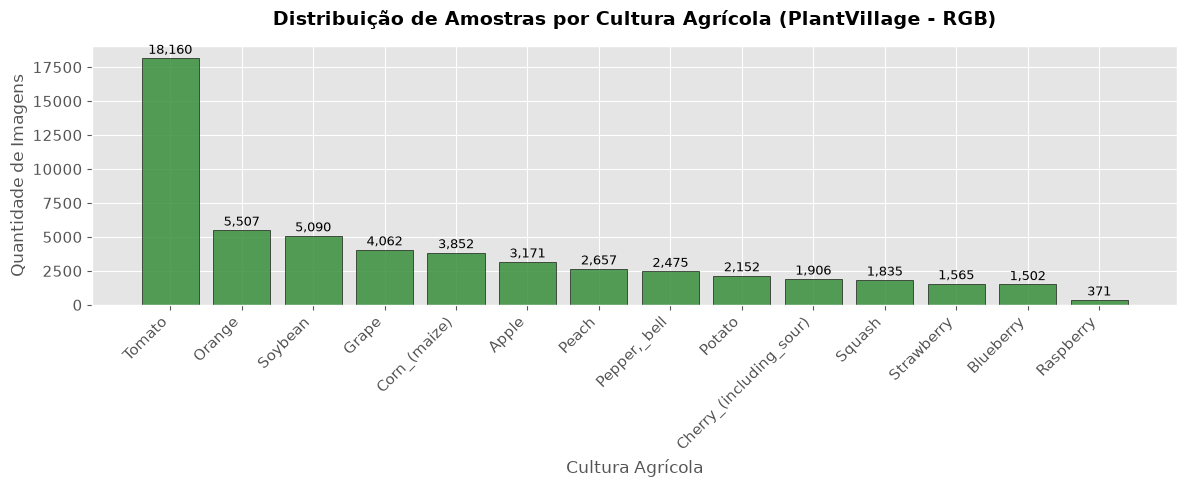

In [10]:
# 4.2 Distribuição por Cultura Agrícola
culturas = df_meta['especie_cultura'].value_counts()

plt.figure(figsize=(12, 5))
bars = plt.bar(culturas.index, culturas.values, color='#388e3c', edgecolor='black', alpha=0.85)
plt.title('Distribuição de Amostras por Cultura Agrícola (PlantVillage - RGB)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Cultura Agrícola', fontsize=12)
plt.ylabel('Quantidade de Imagens', fontsize=12)
plt.xticks(rotation=45, ha='right')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f'{yval:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


### 4.3 Proporção Sanitária: Folhas Saudáveis vs. Infectadas por Fitopatologias


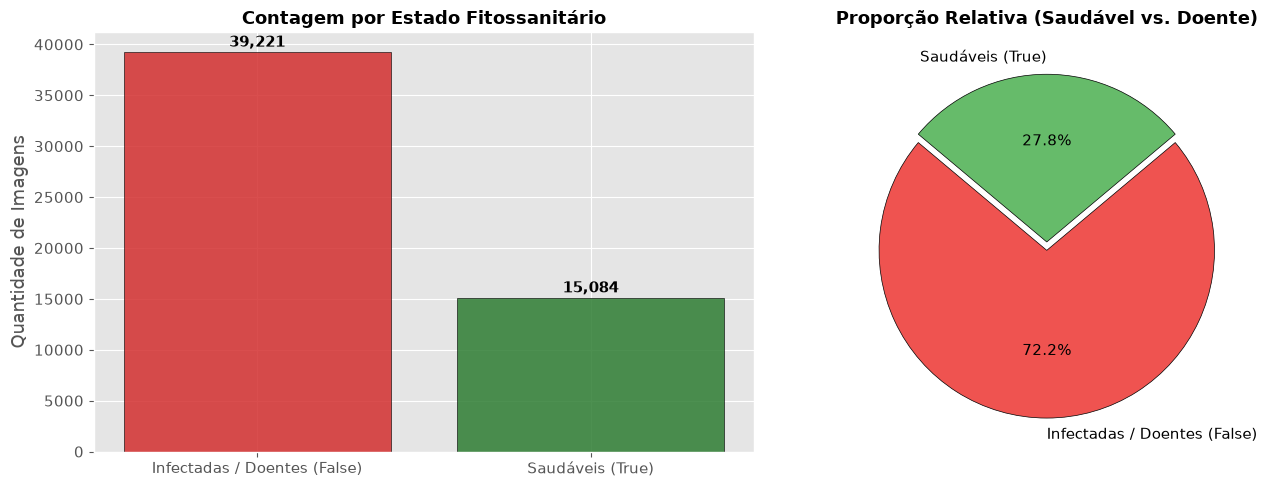

In [11]:
# 4.3 Análise do Estado Sanitário (is_saudavel)
status_counts = df_meta['is_saudavel'].value_counts()
labels = ['Infectadas / Doentes (False)', 'Saudáveis (True)']

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

bars = ax[0].bar(labels, [status_counts.get(False, 0), status_counts.get(True, 0)], color=['#d32f2f', '#2e7d32'], edgecolor='black', alpha=0.85)
ax[0].set_title('Contagem por Estado Fitossanitário', fontsize=13, fontweight='bold')
ax[0].set_ylabel('Quantidade de Imagens')
for bar in bars:
    y = bar.get_height()
    ax[0].text(bar.get_x() + bar.get_width()/2.0, y + 200, f'{y:,}', ha='center', va='bottom', fontweight='bold')

colors = ['#ef5350', '#66bb6a']
ax[1].pie(
    [status_counts.get(False, 0), status_counts.get(True, 0)],
    labels=labels,
    autopct='%1.1f%%',
    colors=colors,
    startangle=140,
    explode=(0.05, 0),
    wedgeprops={'edgecolor': 'black'}
)
ax[1].set_title('Proporção Relativa (Saudável vs. Doente)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


### 4.4 Análise Fotométrica de Cores: Assinatura Espectral RGB


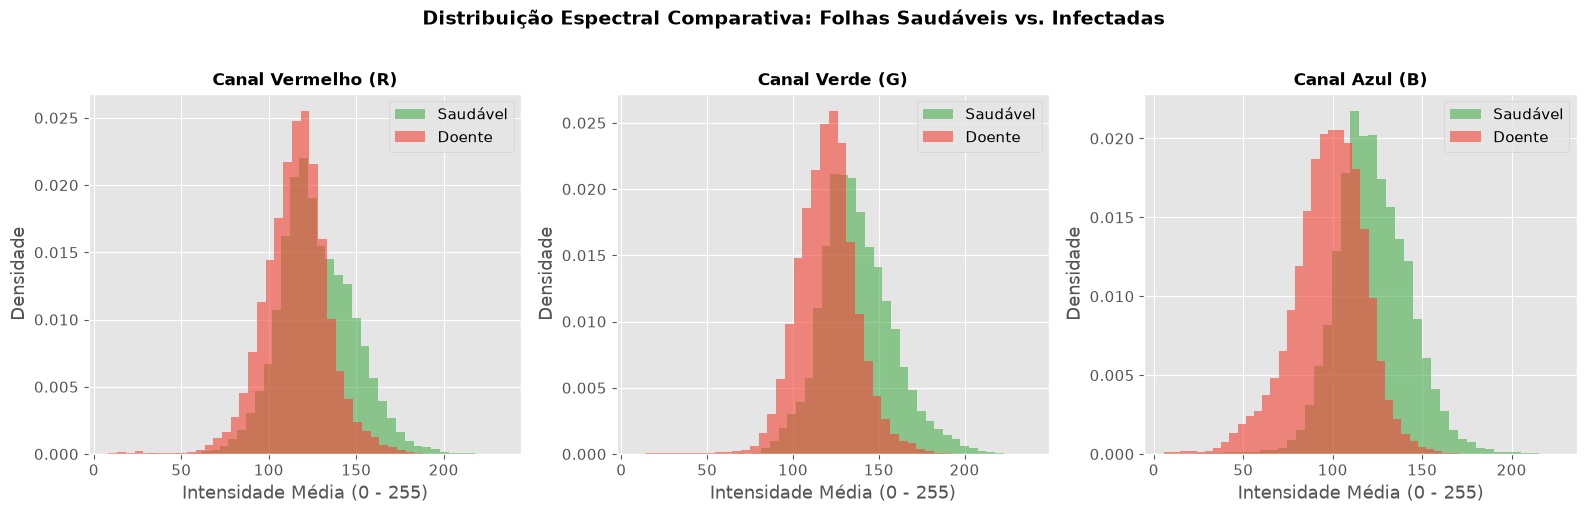

In [12]:
# 4.4 Comparação Fotométrica de Médias de Cores
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
canais = [('media_canal_r', 'Canal Vermelho (R)', '#c62828'),
          ('media_canal_g', 'Canal Verde (G)', '#2e7d32'),
          ('media_canal_b', 'Canal Azul (B)', '#1565c0')]

for i, (col, titulo, cor) in enumerate(canais):
    saudaveis = df_meta[df_meta['is_saudavel'] == True][col]
    doentes = df_meta[df_meta['is_saudavel'] == False][col]
    
    axes[i].hist(saudaveis, bins=40, alpha=0.6, label='Saudável', color='#4caf50', density=True)
    axes[i].hist(doentes, bins=40, alpha=0.6, label='Doente', color='#f44336', density=True)
    axes[i].set_title(titulo, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Intensidade Média (0 - 255)')
    axes[i].set_ylabel('Densidade')
    axes[i].legend()

plt.suptitle('Distribuição Espectral Comparativa: Folhas Saudáveis vs. Infectadas', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 5. Galeria de Amostragem Visual do Acervo

Abaixo selecionamos aleatoriamente amostras de culturas distintas para visualizar as imagens com as anotações do nosso DataFrame de metadados.


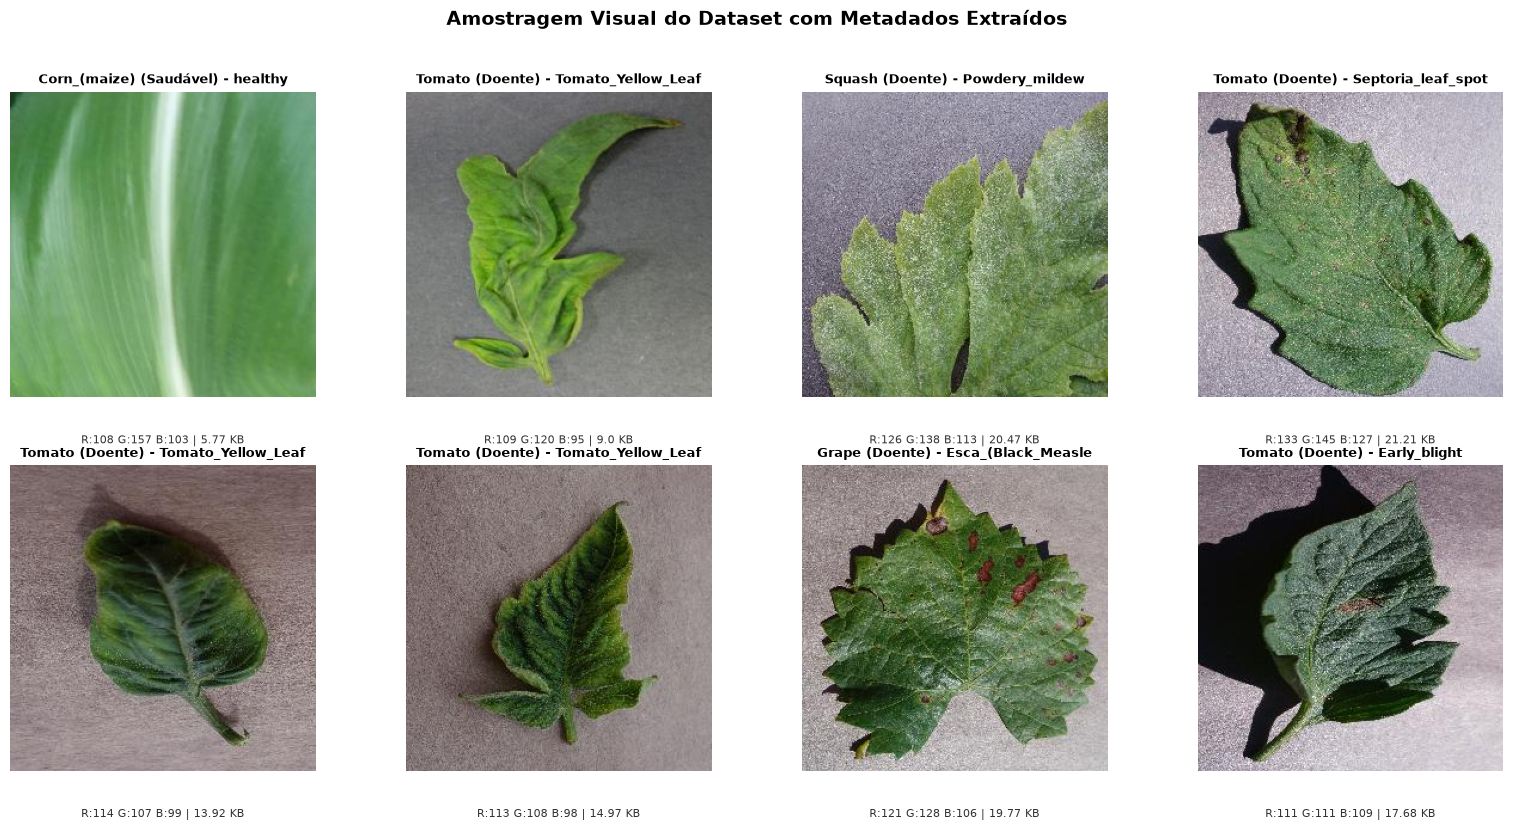

In [13]:
# 5. Visualização de Imagens Amostrais
np.random.seed(42)
amostras = df_meta.sample(8)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

base_proj = Path(csv_path).resolve().parent.parent.parent

for idx, (_, row) in enumerate(amostras.iterrows()):
    caminho_completo = base_proj / row['caminho_arquivo']
    img = Image.open(caminho_completo)
    
    status_str = 'Saudável' if row['is_saudavel'] else 'Doente'
    
    axes[idx].imshow(img)
    titulo = f"{row['especie_cultura']} ({status_str}) - {row['condicao_sanitaria'][:18]}"
    axes[idx].set_title(titulo, fontsize=9, fontweight='bold')
    axes[idx].axis('off')
    
    subinfo = f"R:{row['media_canal_r']:.0f} G:{row['media_canal_g']:.0f} B:{row['media_canal_b']:.0f} | {row['tamanho_arquivo_kb']} KB"
    axes[idx].text(0.5, -0.15, subinfo, transform=axes[idx].transAxes, ha='center', fontsize=8, color='#333')

plt.suptitle('Amostragem Visual do Dataset com Metadados Extraídos', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 6. Conclusões e Próximos Passos (Etapa 3)

1. **Validação Estrutural:** O acervo de imagens apresenta 100% de consistência técnica na resolução de $256 	x 256$ pixels em 3 canais de cor, eliminando a necessidade de reescalonamento destrutivo ou preenchimento de bordas.
2. **Dicionário de Dados:** Todas as 19 colunas especificadas fornecem subsídios sólidos para rastreabilidade, segmentação analítica e treinamento supervisionado.
3. **Próxima Etapa (Etapa 3 - Consolidação do Modelo):**
   - Aplicação de técnicas de pré-processamento (normalização $[0, 1]$, Z-score e Data Augmentation para combater desbalanceamento de classes).
   - Treinamento do modelo de Deep Learning (Redes Neurais Convolucionais - CNN / Transfer Learning).
   - Avaliação por meio de Matriz de Confusão, Acurácia, Precisão, Recall e F1-Score ponderado.
